# Is Bitcoin a Safe Haven? Evidence from the 2026 Strait of Hormuz Crisis

**Author:** Xiang Zheng, University of Toronto

**Question.** When a war or crisis breaks out, investors look for assets that protect them from falling stocks. Research separates two kinds of protection (Baur and Lucey, 2010):

- a **hedge** does not move with stocks on average, on good and bad days alike;
- a **safe haven** holds its value on the days when stocks fall sharply.

Gold is the classic example of both, and some people argue that Bitcoin is "digital gold". This notebook asks whether either of them behaved this way during the 2026 Strait of Hormuz crisis. Most of the 2026 evidence is about the first kind of protection, because the conflict produced only two sharp market falls; the second is tested mainly on 2019–2025.

**How I answer it.**
1. Look at how prices moved around six key moments in the 2026 crisis.
2. Compare how closely Bitcoin and gold followed the stock market, oil, the US dollar and interest rates before and during the conflict, using several different "before" periods.
3. Compare 2026 with six earlier market shocks since 2019.
4. Apply a standard test from academic research (Baur and Lucey, 2010) that looks at the worst days for the stock market in 2019–2025, and compare the few similar days in 2026.

**Data.** Daily prices from the Massive API (formerly Polygon.io) and, for Bitcoin before October 2024, Yahoo Finance. The 10-year inflation-adjusted interest rate comes from FRED (Federal Reserve Bank of St. Louis), which needs no key. The raw prices are not included in this repository because of the data provider's license terms; to reproduce the results, run this notebook with your own Massive API key.

The text explains each step in plain language. Exact model definitions and the key numbers are collected in the **Technical notes** at the end.

## 1. Setup and data download

The API key is typed in when the notebook runs and is never saved in the file.

| Name | Ticker | What it represents |
|---|---|---|
| bitcoin | X:BTCUSD | Bitcoin (trades every day, around the clock) |
| sp500 | SPY | A fund that tracks the S&P 500, the 500 largest US companies |
| gold | GLD | A fund that tracks the price of gold |
| brent | BNO | A fund that tracks Brent crude oil |
| gold_spot | C:XAUUSD | The gold price on the currency market (opens Sunday evening) |
| dollar | UUP | A fund that rises when the US dollar strengthens |
| tips | TIP | A fund of inflation-protected US government bonds (falls when inflation-adjusted interest rates rise) |

In [1]:
from getpass import getpass
from massive import RESTClient
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
import yfinance as yf

client = RESTClient(api_key=getpass("Massive API key: "))

def get_daily(ticker, start="2025-06-01", end="2026-10-09"):
    # Download daily closing prices for one ticker; returns a series indexed by date
    bars = client.list_aggs(ticker=ticker, multiplier=1, timespan="day",
                            from_=start, to=end, adjusted=True, limit=50000)
    df = pd.DataFrame([{"date": pd.to_datetime(b.timestamp, unit="ms", utc=True).date(),
                        "close": b.close} for b in bars])
    s = df.set_index("date")["close"]
    s.index = pd.to_datetime(s.index)
    return s

def empirical_p(reference, value, k):
    # Share of same-length windows in the reference sample with a move at least as large
    # (with the usual +1 correction so the share is never exactly zero)
    windows = reference.rolling(k).sum().dropna()
    return ((windows.abs() >= abs(value)).sum() + 1) / (len(windows) + 1)

def holm(p_values):
    # Holm adjustment for testing many windows at once
    return multipletests(p_values, method="holm")[1]

def event_window(series, start_pos, k):
    # Returns exactly k days starting at start_pos, or stops with an error if data are missing
    w = series.iloc[start_pos:start_pos + k]
    if len(w) != k or w.isna().any():
        raise ValueError(f"Incomplete event window starting {series.index[start_pos].date()}")
    return w

Massive API key:  ········


In [2]:
tickers = {
    "X:BTCUSD": "bitcoin",
    "SPY": "sp500",
    "GLD": "gold",
    "BNO": "brent",
    "C:XAUUSD": "gold_spot",
    "UUP": "dollar",
    "TIP": "tips",
}

prices = pd.DataFrame({name: get_daily(t) for t, name in tickers.items()}).sort_index()
prices.to_csv("prices.csv")   # kept locally only (excluded by .gitignore)
print(prices.shape[0], "days,", prices.shape[1], "assets")

496 days, 7 assets


## 2. Lining up trading days and calculating daily changes

Bitcoin trades every day, the gold currency market trades Sunday to Friday, and the funds trade only on US market days, which is why some values are missing below. To compare like with like, I keep only US trading days, so Bitcoin's Monday change covers the whole weekend. One timing difference remains: Bitcoin's daily price is recorded at midnight UTC, which is 8 p.m. New York time in summer and 7 p.m. in winter, three to four hours after the US stock market closes. Section 7 checks how this affects the results; it changes two of the Bitcoin results.

In [3]:
print("Missing values by column:")
print(prices.isna().sum())

trading = prices.dropna(subset=["sp500"])
returns = np.log(trading / trading.shift(1)).iloc[1:]
returns.head()

Missing values by column:
bitcoin        0
sp500        154
gold         154
brent        154
gold_spot     71
dollar       154
tips         154
dtype: int64


,bitcoin,sp500,gold,brent,gold_spot,dollar,tips
date,,,,,,,
2025-06-03,-0.004326,0.005686,-0.008895,0.007140,-0.008167,0.006581,-0.000921
2025-06-04,-0.006607,-0.000268,0.006421,-0.010730,0.005305,-0.004383,0.003862
2025-06-05,-0.030859,-0.004844,-0.005063,0.006452,-0.004787,-0.000732,-0.002941
2025-06-06,0.027460,0.010217,-0.013507,0.018758,-0.015584,0.005115,-0.005353
2025-06-09,0.055004,0.000901,0.004707,0.007684,0.005175,-0.002554,0.001387


## 3. Events and price paths

Six key moments in the 2026 crisis. Dates come from news timelines, with announcement times where the sources report them. They should ideally be confirmed against original news reports, and I did not check whether other major economic news came out on the same days. The chart then shows how prices moved through 2026.

| Event | Date and time (ET) | First US trading day used | Source |
|---|---|---|---|
| US and Israeli strikes on Iran; Iran declares the strait closed | Sat Feb 28, 2026 (time not reported) | Mon Mar 2 | [Wikipedia: 2026 Strait of Hormuz campaign](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_campaign) |
| Two-week ceasefire announced (takes effect April 8) | Tue Apr 7, early evening: less than two hours before an 8 p.m. ET deadline, so after the US close | Wed Apr 8 | [NPR via Michigan Public](https://www.michiganpublic.org/2026-04-07/trump-backs-down-from-imminent-threat-to-annihilate-iran-announcing-2-week-ceasefire); [Wikipedia: 2026 Iran war ceasefire](https://en.wikipedia.org/wiki/2026_Iran_war_ceasefire) |
| Islamabad talks fail; US announces a naval blockade (effective Apr 13, 10:00 ET) | Sun Apr 12 | Mon Apr 13 | [Wikipedia: 2026 Iran war ceasefire](https://en.wikipedia.org/wiki/2026_Iran_war_ceasefire) |
| Islamabad Memorandum signed; strait reopens June 18 | Wed Jun 17 (signed at an evening dinner in France, during US trading hours) | Wed Jun 17 | [Wikipedia: 2026 Strait of Hormuz campaign](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_campaign) |
| Ceasefire collapses; strait declared closed again on July 11 | Wed Jul 8 (time not reported) | Wed Jul 8 | [hormuz.now timeline](https://hormuz.now/timeline); [Crypto Briefing](https://cryptobriefing.com/iran-strait-hormuz-closure-bitcoin-market-impact/) |
| US forces destroy Iranian tankers after Iran's Revolutionary Guard fires on a US warship | Tue Sep 8 (time not reported) | Tue Sep 8 | [hormuz.now timeline](https://hormuz.now/timeline) |

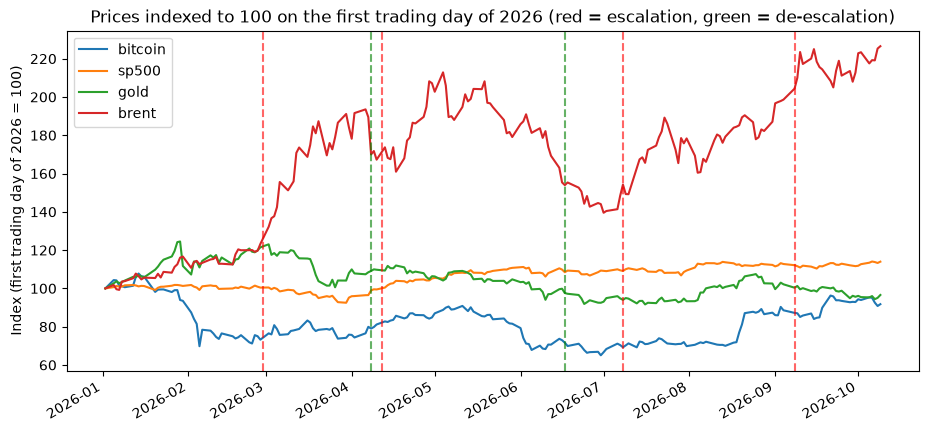

In [4]:
events = pd.DataFrame({
    "date": pd.to_datetime(["2026-02-28", "2026-04-08", "2026-04-12",
                            "2026-06-17", "2026-07-08", "2026-09-08"]),
    "label": ["War begins", "Ceasefire", "Blockade",
              "MOU signed", "Ceasefire collapses", "Tanker strikes"],
    "type": ["escalation", "de-escalation", "escalation",
             "de-escalation", "escalation", "escalation"],
})

def add_event_lines(ax):
    for _, e in events.iterrows():
        color = "red" if e["type"] == "escalation" else "green"
        ax.axvline(e["date"], color=color, linestyle="--", alpha=0.6)

norm = trading.loc["2026-01-01":, ["bitcoin", "sp500", "gold", "brent"]]
norm = norm / norm.iloc[0] * 100

fig, ax = plt.subplots(figsize=(11, 5))
norm.plot(ax=ax)
add_event_lines(ax)
ax.set_title("Prices indexed to 100 on the first trading day of 2026 (red = escalation, green = de-escalation)")
ax.set_ylabel("Index (first trading day of 2026 = 100)")
ax.set_xlabel("")
plt.savefig("figures/price_paths.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. How did prices react on key days?

For each event, I compare each asset's move over the first two US trading days with its normal behaviour in a "before" period, June 2025 to January 2026. This period ends before the war and before an unrelated Bitcoin crash in early February 2026. It is not completely calm, because it includes the 12-day Israel–Iran conflict of June 2025, so Section 6 also checks other "before" periods.

The table shows each move in percent (strictly, as a log change, which is very close to the ordinary percentage change for moves of a few percent), together with a score of how unusual it is: a score beyond about 2 in either direction means the move was bigger than normal day-to-day swings.

In [5]:
baseline = returns.loc["2025-06-01":"2026-01-30"]
mu = baseline.mean()
sigma = baseline.std()
abnormal = returns - mu

def car(event_date, start, end):
    pos = abnormal.index.searchsorted(event_date)   # first trading day on or after the event
    return abnormal.iloc[pos + start : pos + end + 1].sum()

assets = ["bitcoin", "sp500", "gold", "brent"]
rows = []
for _, e in events.iterrows():
    c = car(e["date"], 0, 1)
    t = c / (sigma * np.sqrt(2))
    row = {"event": e["label"], "type": e["type"]}
    for a in assets:
        row[a] = round(c[a] * 100, 2)
        row[a + "_t"] = round(t[a], 2)
    rows.append(row)

car_table = pd.DataFrame(rows)
car_table

,event,type,bitcoin,bitcoin_t,sp500,sp500_t,gold,gold_t,brent,brent_t
0,War begins,escalation,3.95,1.19,-1.01,-1.07,-3.71,-1.71,10.16,4.05
1,Ceasefire,de-escalation,0.12,0.04,2.90,3.06,0.98,0.45,-10.01,-3.99
2,Blockade,escalation,1.88,0.57,2.00,2.11,1.38,0.64,0.35,0.14
3,MOU signed,de-escalation,-3.99,-1.20,-0.67,-0.70,-3.11,-1.43,-0.22,-0.09
4,Ceasefire collapses,escalation,0.04,0.01,0.35,0.37,-0.24,-0.11,0.37,0.15
5,Tanker strikes,escalation,-1.49,-0.45,-1.20,-1.27,-1.27,-0.59,5.36,2.14


**Reading the table.** Oil reacts most clearly, which confirms that these dates were real shocks. None of Bitcoin's moves is bigger than its normal swings. Bitcoin swings so much from day to day (about 2.3%) that it would need to move about 6–7% in two days to stand out, so this does not prove that it did not react.

### Taking out the stock market's influence

The table above compares each asset with its own average. But if stocks fell sharply on an event day, Bitcoin might fall simply because it usually follows stocks. Here I first take out the part of each move that the stock market explains, based on how closely each asset followed stocks in the before period, and look at what is left over one, two and three trading days after each event.

To judge whether a move is unusual, I count how often a move at least that large happened in the before period. If that share is below 5%, the move is rare on its own. Because the table makes 36 comparisons, a few will look rare by chance alone. I treat the two-day window (the first trading day and the next) as the main test; the last column adjusts its 12 results (six events, two assets) for the number of comparisons, and the column before it adjusts all 36 together. A result counts as clearly rare only if its adjusted figure is also below 5%. As in the table above, moves are log changes, which are very close to ordinary percentage changes for moves of a few percent.

In [6]:
market_model = {a: smf.ols(f"{a} ~ sp500", data=baseline).fit() for a in ["bitcoin", "gold"]}
ar_mm = pd.DataFrame({a: returns[a] - (m.params["Intercept"] + m.params["sp500"] * returns["sp500"])
                      for a, m in market_model.items()})

rows = []
for _, e in events.iterrows():
    pos = ar_mm.index.searchsorted(e["date"])
    for k in [1, 2, 3]:
        for a in ["bitcoin", "gold"]:
            c = event_window(ar_mm[a], pos, k).sum()
            rows.append({"event": e["label"], "asset": a, "days": k,
                         "abnormal_log_pct": round(100 * c, 2),
                         "emp_p": empirical_p(ar_mm.loc[baseline.index, a], c, k)})
mm_table = pd.DataFrame(rows)
mm_table["emp_p_holm"] = holm(mm_table["emp_p"])   # adjusted for all 36 windows
main = mm_table["days"] == 2                       # main test: first trading day and the next
mm_table.loc[main, "emp_p_holm_main"] = holm(mm_table.loc[main, "emp_p"])   # adjusted for 12 windows
mm_table.round(3)

,event,asset,days,abnormal_log_pct,emp_p,emp_p_holm,emp_p_holm_main
0,War begins,bitcoin,1,4.60,0.042,1.000,NaN
1,War begins,gold,1,1.07,0.298,1.000,NaN
2,War begins,bitcoin,2,5.84,0.042,1.000,0.503
3,War begins,gold,2,-3.63,0.066,1.000,0.659
4,War begins,bitcoin,3,11.01,0.006,0.217,NaN
5,War begins,gold,3,-3.11,0.175,1.000,NaN
6,Ceasefire,bitcoin,1,-5.53,0.018,0.625,NaN
7,Ceasefire,gold,1,0.23,0.815,1.000,NaN
8,Ceasefire,bitcoin,2,-5.30,0.060,1.000,0.659
9,Ceasefire,gold,2,0.75,0.611,1.000,1.000


**Reading the table.** Gold shows no consistent reaction: only one of its 18 results is rare on its own, about what chance alone would produce. Bitcoin looks more striking. After allowing for the stock market, it did about 4.6% better than expected on the first trading day after the war began (about 11% over three days) and about 5.5% worse than expected on the first trading day of the ceasefire.

However, once the number of comparisons is taken into account, none of the results in the table is clearly rare, either in the main two-day test or across all 36 windows. In addition, Bitcoin followed stocks unusually closely in the before period, which exaggerates how far it "should" have moved, and Section 7 shows that the ceasefire result disappears when Bitcoin's price is taken at the US close. So I treat this part as supporting evidence only. These comparisons with past moves, and the adjustments for the number of comparisons, are exploratory: they are still affected by changes in how turbulent markets are and by overlapping windows.

## 5. Did Bitcoin and gold start moving together?

I measure how closely Bitcoin's daily moves matched those of stocks, gold, oil and the other assets, before and during the war (the war period starts on March 2, 2026, the first US trading day after it began).

One caution from earlier research (Forbes and Rigobon, 2002): these measures tend to rise automatically when markets become more turbulent, so I treat them as supporting evidence only.

In [7]:
calm = returns.loc["2025-06-01":"2026-01-30"]
war = returns.loc["2026-03-02":]

corr_table = pd.DataFrame({
    "baseline (Jun 2025 - Jan 2026)": calm.corr()["bitcoin"],
    "war (Mar - Oct 2026)": war.corr()["bitcoin"],
}).round(2)
corr_table

,baseline (Jun 2025 - Jan 2026),war (Mar - Oct 2026)
bitcoin,1.00,1.00
sp500,0.53,0.41
gold,0.10,0.43
brent,0.03,-0.18
gold_spot,0.12,0.47
dollar,-0.04,-0.26
tips,0.13,0.14


### Does their shared link to stocks explain why Bitcoin and gold moved together?

If Bitcoin and gold moved together during the war only because both were following the stock market, the link between them should mostly disappear once each asset's stock-market-driven moves are taken out. I take those moves out and measure the link between what is left. This splits the link into parts; it does not prove what caused it.

In [8]:
def resid_on_stocks(data, y):
    return smf.ols(f"{y} ~ sp500", data=data).fit().resid

for period_name, data in [("baseline", calm), ("war", war)]:
    raw = data["bitcoin"].corr(data["gold"])
    partial = resid_on_stocks(data, "bitcoin").corr(resid_on_stocks(data, "gold"))
    print(f"{period_name:5s} Bitcoin-gold correlation: raw {raw:.2f}, after removing stock-market moves {partial:.2f}")

baseline Bitcoin-gold correlation: raw 0.10, after removing stock-market moves 0.10
war   Bitcoin-gold correlation: raw 0.43, after removing stock-market moves 0.29


**Reading the output.** Bitcoin's link with gold rose from about 0.10 before the war to 0.43 during it. Taking out each asset's stock-market-driven moves lowers the war-period figure to 0.29, so their shared link to stocks explains part, but not all, of the closer link between them.

## 6. Did the link to stocks change during the war?

I combine the before period and the war period and test directly whether Bitcoin and gold followed the stock market more or less closely during the war, while also allowing for oil, the dollar and interest rates. Each of the four links is allowed to change during the war.

In [9]:
pooled = pd.concat([calm.assign(war=0), war.assign(war=1)]).sort_index()

for y in ["gold", "bitcoin"]:
    m = smf.ols(f"{y} ~ war * (sp500 + dollar + brent + tips)", data=pooled) \
           .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(f"\n=== {y} ===")
    print(m.summary().tables[1])


=== gold ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0019      0.001      1.873      0.061   -9.07e-05       0.004
war           -0.0033      0.002     -1.964      0.050      -0.007   -6.26e-06
sp500          0.0194      0.173      0.112      0.911      -0.319       0.358
dollar        -1.1222      0.356     -3.155      0.002      -1.819      -0.425
brent          0.0669      0.047      1.430      0.153      -0.025       0.159
tips           0.0159      0.408      0.039      0.969      -0.783       0.815
war:sp500      0.7366      0.287      2.566      0.010       0.174       1.299
war:dollar    -0.2093      0.735     -0.285      0.776      -1.651       1.232
war:brent     -0.0350      0.061     -0.575      0.566      -0.154       0.084
war:tips       0.5195      0.605      0.858      0.391      -0.667       1.706

=== bitcoin ===
                 coef

**Reading the output.** Gold's link to stocks was clearly stronger during the war, by about 0.74 on a scale where 1 means moving as much as stocks. Bitcoin's was weaker by about the same amount, although Section 7 shows that this is less clear when Bitcoin's price is taken at the US close.

**Caveat.** These changes are measured against June 2025 to January 2026. That period includes the June 2025 Israel–Iran conflict, and Bitcoin followed stocks unusually closely in it. The next part tests other before periods.

### Does the choice of "before" period matter?

I repeat the test with three other before periods: the last 60, 120 and 180 trading days before the war. The "change in war" column shows how much more closely each asset followed stocks during the war than in that period.

In [10]:
pre_war = returns.loc[:"2026-02-27"]
baselines = {
    "Jun 2025 - Jan 2026 (main)": calm,
    "60 trading days before the war": pre_war.iloc[-60:],
    "120 trading days before the war": pre_war.iloc[-120:],
    "180 trading days before the war": pre_war.iloc[-180:],
}

rows = []
for name, base in baselines.items():
    pooled_b = pd.concat([base.assign(war=0), war.assign(war=1)]).sort_index()
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ war * (sp500 + dollar + brent + tips)", data=pooled_b) \
               .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["war:sp500"]
        rows.append({"baseline": name, "asset": asset, "baseline_days": len(base),
                     "baseline_beta": m.params["sp500"],
                     "war_beta": m.params["sp500"] + m.params["war:sp500"],
                     "change_in_war": m.params["war:sp500"],
                     "ci_low": lo, "ci_high": hi, "p_value": m.pvalues["war:sp500"]})
baseline_check = pd.DataFrame(rows).round(3)
pd.set_option("display.max_columns", None)
baseline_check

,baseline,asset,baseline_days,baseline_beta,war_beta,change_in_war,ci_low,ci_high,p_value
0,Jun 2025 - Jan 2026 (main),gold,167,0.019,0.756,0.737,0.174,1.299,0.010
1,Jun 2025 - Jan 2026 (main),bitcoin,167,1.862,1.119,-0.744,-1.430,-0.057,0.034
2,60 trading days before the war,gold,60,0.209,0.756,0.547,-0.393,1.486,0.254
3,60 trading days before the war,bitcoin,60,3.139,1.119,-2.020,-3.865,-0.175,0.032
4,120 trading days before the war,gold,120,0.273,0.756,0.483,-0.180,1.146,0.154
5,120 trading days before the war,bitcoin,120,2.527,1.119,-1.408,-2.469,-0.348,0.009
6,180 trading days before the war,gold,180,0.092,0.756,0.664,0.067,1.260,0.029
7,180 trading days before the war,bitcoin,180,2.245,1.119,-1.127,-2.068,-0.186,0.019


**Reading the table.** Gold followed stocks more closely during the war than in every before period, but the increase is clearly bigger than chance for only two of the four: the main period and the 180 days before the war. The shorter periods give weaker results partly because gold had already started to follow stocks in the last few months before the war, so part of the change began before the war started.

The main before period is itself mixed. Section 8 shows that gold moved against stocks in the summer of 2025 and with them by the winter, so its overall figure of about 0.08 averages two very different stretches, and part of the increase measured against it is a rebound from an unusually low summer. The 60- and 120-day periods start after that summer dip; the 180-day period, which starts in June 2025, does not. This is why the main conclusions are also compared with gold's 2019–2025 level (likewise about 0.08).

Bitcoin followed stocks less closely during the war under every before period, but only because it had followed them unusually closely just before the war. During the war it moved roughly as much as stocks, close to its usual 2019–2025 behaviour, so this is a return to normal, not a sign that Bitcoin became a safe haven.

### Check: a direct measure of interest rates

One explanation for gold following stocks is that both reacted to the same news about interest rates: the oil shock raised inflation worries, and on days when markets expected higher inflation-adjusted interest rates, both stocks and gold (which pays no interest) tended to fall. The TIPS fund used so far is only a rough stand-in for these rates, because its price also depends on how long its bonds run and on inflation itself. Here I replace it with the daily change in the 10-year inflation-adjusted interest rate on US government bonds, from the Federal Reserve Bank of St. Louis, and repeat the main test. If shared exposure to interest rates explained the change, the extra link between gold and stocks during the war should shrink towards zero.

In [11]:
def get_fred(series_id, start="2019-01-01"):
    # Daily series from FRED (no API key needed); FRED marks missing days with "."
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}&cosd={start}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    return s.astype(float).dropna()

# Daily change in the 10-year real yield, in percentage points, from the previous day with data
real_yield = get_fred("DFII10", start="2025-05-01").diff().rename("real_yield")

pooled_ry = (pd.concat([calm.assign(war=0), war.assign(war=1)])
               .join(real_yield, how="left")
               .dropna(subset=["real_yield"])     # drops days when the bond market was closed
               .sort_index())

rows = []
for asset in ["gold", "bitcoin"]:
    for label, rate in [("TIPS fund (same days)", "tips"), ("10-year real yield", "real_yield")]:
        m = smf.ols(f"{asset} ~ war * (sp500 + dollar + brent + {rate})", data=pooled_ry) \
               .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["war:sp500"]
        rows.append({"asset": asset, "interest_rate_measure": label, "days": int(m.nobs),
                     "change_in_war": m.params["war:sp500"], "ci_low": lo, "ci_high": hi,
                     "p_value": m.pvalues["war:sp500"],
                     "rate_link_before": m.params[rate],
                     "rate_link_war": m.params[rate] + m.params[f"war:{rate}"]})
real_yield_check = pd.DataFrame(rows)
# For the real-yield rows, also show the link in plain units:
# % move in the asset for a 0.10 percentage-point (10 basis point) rise in the real yield
ry = real_yield_check["interest_rate_measure"] == "10-year real yield"
for col in ["rate_link_before", "rate_link_war"]:
    real_yield_check.loc[ry, col.replace("rate_link", "pct_move_per_10bp_rise")] = real_yield_check.loc[ry, col] * 0.10 * 100
real_yield_check.round(4)

,asset,interest_rate_measure,days,change_in_war,ci_low,ci_high,p_value,rate_link_before,rate_link_war,pct_move_per_10bp_rise_before,pct_move_per_10bp_rise_war
0,gold,TIPS fund (same days),320,0.7880,0.2208,1.3551,0.0065,-0.0721,0.5354,NaN,NaN
1,gold,10-year real yield,320,0.7568,0.1863,1.3272,0.0093,0.0004,-0.0415,0.0041,-0.4149
2,bitcoin,TIPS fund (same days),320,-0.7677,-1.4643,-0.0711,0.0308,1.1936,-0.2261,NaN,NaN
3,bitcoin,10-year real yield,320,-0.8027,-1.5351,-0.0702,0.0317,-0.0590,-0.0044,-0.5901,-0.0444


**Reading the table.** Swapping the TIPS fund for the inflation-adjusted interest rate barely changes gold's extra link to stocks during the war (0.76 instead of 0.79, still clearly bigger than chance). So the main result is still there with a direct measure of interest rates. This check cannot rule out every role for interest rates, but it gives no support to the idea that gold and stocks moved together mainly because both were reacting to the same interest-rate news. Bitcoin's result also barely changes.

The last two columns show something else. Before the war, gold hardly reacted to this interest rate at all; during the war it tended to fall by about 0.4% for each 0.1 percentage-point rise. So gold did become more sensitive to interest rates during the conflict, but allowing for this leaves its closer link with stocks in place.

## 7. Checking the data and building a longer history

My Massive data plan covers Bitcoin for only two years, so Bitcoin prices before October 2024 come from Yahoo Finance. Where both sources overlap, I check that they give the same daily moves. The long history from 2019 onward then uses Yahoo Finance for Bitcoin and Massive for everything else.

In [12]:
btc_yf = yf.download("BTC-USD", start="2019-01-01", end="2026-10-10",
                     auto_adjust=True)["Close"].squeeze()
btc_yf.index = pd.to_datetime(btc_yf.index).tz_localize(None)

both = pd.DataFrame({"massive": prices["bitcoin"], "yfinance": btc_yf}).dropna()
r = np.log(both / both.shift(1)).dropna()
print(len(r), "overlapping days")
r.corr()

[*********************100%***********************]  1 of 1 completed

495 overlapping days


,massive,yfinance
massive,1.000000,0.999531
yfinance,0.999531,1.000000


In [13]:
hist = pd.DataFrame({name: get_daily(t, start="2019-01-01")
                     for t, name in {"SPY": "sp500", "GLD": "gold",
                                     "BNO": "brent", "UUP": "dollar"}.items()})
hist["bitcoin"] = btc_yf
hist = hist.sort_index().dropna(subset=["sp500"])
hret = np.log(hist / hist.shift(1)).iloc[1:]
hret.tail()

,sp500,gold,brent,dollar,bitcoin
date,,,,,
2026-10-05,0.006721,-0.001553,-0.026497,0.003455,0.015144
2026-10-06,0.005483,0.007141,0.007781,-0.003109,-0.002673
2026-10-07,-0.002403,-0.016857,-0.000485,0.004833,-0.027030
2026-10-08,-0.004242,0.007263,0.027722,-0.002068,-0.019395
2026-10-09,0.005977,0.015619,0.005485,0.001379,0.010595


### Check: Bitcoin priced at the US market close

Bitcoin's daily price above is recorded at midnight UTC, which is 8 p.m. New York time in summer and 7 p.m. in winter, three to four hours after the US stock market closes. Here I rebuild it from hourly prices using the price at 4 p.m., when US stocks close, and check whether the 2026 results change.

In [14]:
import time

def get_hourly(ticker, start, end, chunk_days=30, pause=13):
    # Download hourly bars one month at a time, pausing between requests to stay under the API rate limit
    pieces = []
    for s in pd.date_range(start, end, freq=f"{chunk_days}D"):
        e = min(s + pd.Timedelta(days=chunk_days - 1), pd.Timestamp(end))
        for attempt in range(5):
            try:
                bars = list(client.list_aggs(ticker=ticker, multiplier=1, timespan="hour",
                                             from_=s.strftime("%Y-%m-%d"), to=e.strftime("%Y-%m-%d"),
                                             adjusted=True, limit=50000))
                break
            except Exception:
                print(f"  rate limit hit, waiting 60 seconds (attempt {attempt + 1} of 5)")
                time.sleep(60)
        else:
            raise RuntimeError(f"could not download {s.date()} to {e.date()}")
        pieces += [{"t": pd.to_datetime(b.timestamp, unit="ms", utc=True), "close": b.close} for b in bars]
        print(f"{s.date()} to {e.date()}: {len(bars)} hourly bars")
        time.sleep(pause)
    df = pd.DataFrame(pieces).drop_duplicates("t").set_index("t").sort_index()
    return df["close"].tz_convert("America/New_York")

btc_hourly = get_hourly("X:BTCUSD", "2025-06-01", "2026-10-09")
# The hourly bar that starts at 15:00 ET closes at 16:00 ET
btc_4pm = btc_hourly[btc_hourly.index.hour == 15].copy()
btc_4pm.index = btc_4pm.index.tz_localize(None).normalize()

close_aligned = trading[["sp500", "gold"]].join(btc_4pm.rename("bitcoin_4pm"), how="left")
ret_4pm = np.log(close_aligned / close_aligned.shift(1)).iloc[1:]
ret_4pm["bitcoin"] = returns["bitcoin"]

rows = []
for period_name, data in [("baseline", ret_4pm.loc["2025-06-01":"2026-01-30"]), ("war", ret_4pm.loc["2026-03-02":])]:
    for col in ["bitcoin", "bitcoin_4pm"]:
        d = data[[col, "sp500", "gold"]].dropna()
        rows.append({"period": period_name, "bitcoin_price_time": "midnight UTC" if col == "bitcoin" else "4 p.m. ET",
                     "days": len(d),
                     "beta_to_sp500": d[col].cov(d["sp500"]) / d["sp500"].var(),
                     "corr_with_sp500": d[col].corr(d["sp500"]),
                     "corr_with_gold": d[col].corr(d["gold"])})
btc_time_check = pd.DataFrame(rows).round(3)
btc_time_check

2025-06-01 to 2025-06-30: 720 hourly bars
2025-07-01 to 2025-07-30: 720 hourly bars
2025-07-31 to 2025-08-29: 720 hourly bars
2025-08-30 to 2025-09-28: 720 hourly bars
2025-09-29 to 2025-10-28: 720 hourly bars
2025-10-29 to 2025-11-27: 720 hourly bars
2025-11-28 to 2025-12-27: 720 hourly bars
2025-12-28 to 2026-01-26: 720 hourly bars
2026-01-27 to 2026-02-25: 720 hourly bars
2026-02-26 to 2026-03-27: 720 hourly bars
2026-03-28 to 2026-04-26: 720 hourly bars
2026-04-27 to 2026-05-26: 720 hourly bars
2026-05-27 to 2026-06-25: 720 hourly bars
2026-06-26 to 2026-07-25: 720 hourly bars
2026-07-26 to 2026-08-24: 720 hourly bars
2026-08-25 to 2026-09-23: 720 hourly bars
2026-09-24 to 2026-10-09: 384 hourly bars


,period,bitcoin_price_time,days,beta_to_sp500,corr_with_sp500,corr_with_gold
0,baseline,midnight UTC,167,1.865,0.533,0.103
1,baseline,4 p.m. ET,167,1.715,0.465,0.057
2,war,midnight UTC,155,1.138,0.408,0.433
3,war,4 p.m. ET,155,1.374,0.476,0.450


**Reading the table.** In this simple comparison, the 4 p.m. price changes little: during the war Bitcoin still moved slightly more than stocks (1.37 instead of 1.14 on a scale where 1 means moving as much as stocks), and its link with gold is almost the same (0.45 instead of 0.43), so the timing difference does not explain why Bitcoin and gold moved together. Whether Bitcoin's link to stocks changed during the war is tested in the next part, and there the price time does matter.

### Check: the timing-sensitive results with Bitcoin's 4 p.m. price

The table above is a simple comparison. Here I repeat the two Bitcoin results that depend on timing with the 4 p.m. price: a stocks-only version of the before-versus-war test from Section 6 and the two-day event windows from Section 4. With the 4 p.m. price, Bitcoin and stocks share the same daily cut-off, so news after the US close lands on the next trading day for both. This also matters for the ceasefire, which was announced on the evening of April 7, after the US close: with the midnight UTC price, part of Bitcoin's reaction may fall on April 7 itself.

In [15]:
r4 = ret_4pm.rename(columns={"bitcoin_4pm": "btc_4pm"})
calm4 = r4.loc["2025-06-01":"2026-01-30"].dropna(subset=["btc_4pm"])
war4 = r4.loc["2026-03-02":].dropna(subset=["btc_4pm"])
pooled4 = pd.concat([calm4.assign(war=0), war4.assign(war=1)]).sort_index()

rows = []
for col, label in [("bitcoin", "midnight UTC"), ("btc_4pm", "4 p.m. ET")]:
    m = smf.ols(f"{col} ~ sp500 + war + war:sp500", data=pooled4).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    lo, hi = m.conf_int().loc["war:sp500"]
    rows.append({"bitcoin_price_time": label, "baseline_beta": m.params["sp500"],
                 "war_beta": m.params["sp500"] + m.params["war:sp500"],
                 "change_in_war": m.params["war:sp500"], "ci_low": lo, "ci_high": hi,
                 "p_value": m.pvalues["war:sp500"]})
display(pd.DataFrame(rows).round(3))

# Two-day event windows (main test of Section 4) with the 4 p.m. price
mm4 = smf.ols("btc_4pm ~ sp500", data=calm4).fit()
ar4 = (r4["btc_4pm"] - (mm4.params["Intercept"] + mm4.params["sp500"] * r4["sp500"])).dropna()
rows = []
for _, e in events.iterrows():
    pos = ar4.index.searchsorted(e["date"])
    c = event_window(ar4, pos, 2).sum()
    rows.append({"event": e["label"], "abnormal_log_pct_4pm": round(100 * c, 2),
                 "emp_p": empirical_p(ar4.loc[calm4.index], c, 2)})
event_4pm = pd.DataFrame(rows)
event_4pm["emp_p_holm"] = holm(event_4pm["emp_p"])   # adjusted for 6 events
event_4pm.round(3)

,bitcoin_price_time,baseline_beta,war_beta,change_in_war,ci_low,ci_high,p_value
0,midnight UTC,1.865,1.138,-0.727,-1.269,-0.185,0.009
1,4 p.m. ET,1.715,1.374,-0.341,-0.879,0.198,0.215


,event,abnormal_log_pct_4pm,emp_p,emp_p_holm
0,War begins,6.00,0.042,0.251
1,Ceasefire,-0.29,0.898,1.000
2,Blockade,-1.88,0.455,1.000
3,MOU signed,-2.88,0.281,1.000
4,Ceasefire collapses,-1.25,0.635,1.000
5,Tanker strikes,0.31,0.898,1.000


**Reading the tables.** First table: with the 4 p.m. price, Bitcoin still moved more than stocks both before and during the war (1.72 and 1.37 on a scale where 1 means moving as much as stocks), but the drop between the two periods is smaller (0.34 instead of 0.73) and no longer clearly bigger than chance. So the earlier finding that Bitcoin followed stocks less closely during the war partly reflects when its price is recorded.

Second table: with the 4 p.m. price, the apparent fall after the ceasefire disappears (−0.3%). The ceasefire was announced less than two hours before an 8 p.m. New York deadline on April 7, after the US close but before Bitcoin's midnight UTC price was recorded (8 p.m. New York time). So with the midnight price, Bitcoin's reaction to the news was recorded on April 7, before the window starts, while the stock market's rally was recorded on April 8, which made Bitcoin look as if it had lagged behind. The rise after the war began remains (about 6% more than expected over two days), but it is not clearly rare once the six comparisons are taken into account.

## 8. Was 2026 unusual? Comparison with earlier market shocks

I measure how closely gold and Bitcoin followed the stock market during seven market shocks since 2019, and over all days in 2019–2025 for comparison. On this scale, 0 means no link to stocks and 1 means moving as much as stocks, in the same direction. The time windows are my own choices.

In [16]:
episodes = {
    "COVID crash (2020)":             ("2020-02-24", "2020-04-30", "financial stress"),
    "Russia invades Ukraine (2022)":  ("2022-02-24", "2022-06-30", "oil/inflation"),
    "SVB collapse (2023)":            ("2023-03-08", "2023-04-28", "financial stress"),
    "Yen carry unwind (2024)":        ("2024-07-15", "2024-09-13", "financial stress"),
    "Liberation Day tariffs (2025)":  ("2025-04-03", "2025-05-30", "financial stress"),
    "Israel strikes Iran (2025)":     ("2025-06-13", "2025-07-31", "oil/inflation"),
    "Hormuz war (2026)":              ("2026-03-02", "2026-10-09", "oil/inflation"),
    "All days 2019-2025 (benchmark)": ("2019-01-01", "2025-12-31", "benchmark"),
}

def beta(df, asset):
    return df[asset].cov(df["sp500"]) / df["sp500"].var()

In [17]:
rows = []
for name, (start, end, kind) in episodes.items():
    d = hret.loc[start:end]
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["sp500"]
        rows.append({"episode": name, "asset": asset,
                     "beta": round(m.params["sp500"], 2),
                     "ci_low": round(lo, 2), "ci_high": round(hi, 2),
                     "p_value": round(m.pvalues["sp500"], 3)})
beta_ci = pd.DataFrame(rows)
beta_ci

,episode,asset,beta,ci_low,ci_high,p_value
0,COVID crash (2020),gold,0.10,-0.00,0.19,0.053
1,COVID crash (2020),bitcoin,1.14,0.39,1.90,0.003
2,Russia invades Ukraine (2022),gold,-0.06,-0.22,0.09,0.435
3,Russia invades Ukraine (2022),bitcoin,1.70,1.01,2.40,0.000
4,SVB collapse (2023),gold,-0.55,-0.89,-0.20,0.002
5,SVB collapse (2023),bitcoin,0.54,-0.42,1.50,0.273
6,Yen carry unwind (2024),gold,0.41,0.28,0.54,0.000
7,Yen carry unwind (2024),bitcoin,2.08,0.84,3.32,0.001
8,Liberation Day tariffs (2025),gold,0.00,-0.37,0.38,0.981
9,Liberation Day tariffs (2025),bitcoin,0.50,0.16,0.84,0.004


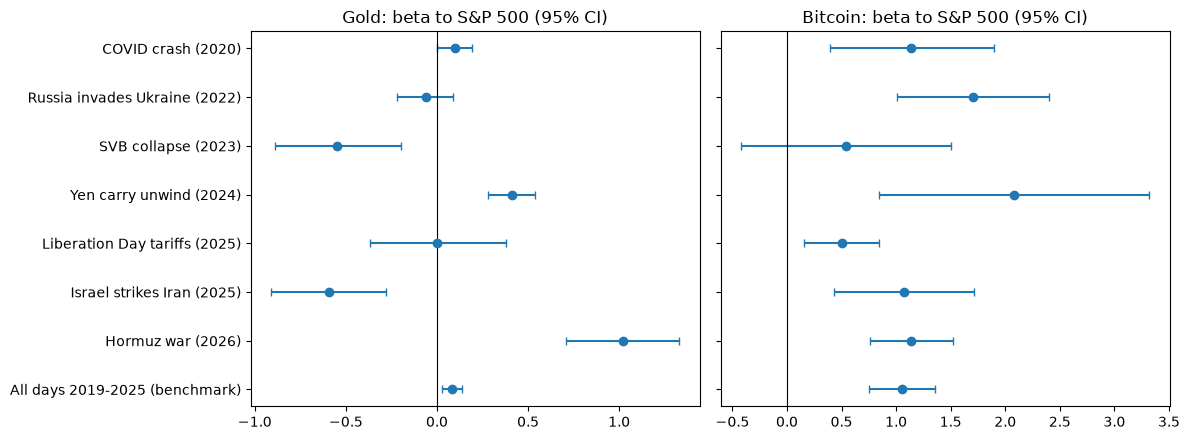

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, asset in zip(axes, ["gold", "bitcoin"]):
    d = beta_ci[beta_ci["asset"] == asset].reset_index(drop=True)
    y = range(len(d))
    ax.errorbar(d["beta"], y,
                xerr=[d["beta"] - d["ci_low"], d["ci_high"] - d["beta"]],
                fmt="o", capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{asset.capitalize()}: beta to S&P 500 (95% CI)")
    ax.set_yticks(list(y))
    ax.set_yticklabels(d["episode"])
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig("figures/beta_by_episode.png", dpi=150, bbox_inches="tight")
plt.show()

### Check: same-length windows

The windows above range from 33 to 155 trading days, so some mix early panic with later recovery more than others. Here every shock uses only its first 40 trading days.

In [19]:
rows = []
for name, (start, end, kind) in episodes.items():
    if kind == "benchmark":
        continue
    d = hret.loc[start:].iloc[:40]   # first 40 trading days from the start, regardless of the original window
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["sp500"]
        rows.append({"episode": name, "asset": asset, "days": len(d),
                     "first_day": d.index[0].date(), "last_day": d.index[-1].date(),
                     "beta": round(m.params["sp500"], 2),
                     "ci_low": round(lo, 2), "ci_high": round(hi, 2)})
beta_40 = pd.DataFrame(rows)
beta_40

,episode,asset,days,first_day,last_day,beta,ci_low,ci_high
0,COVID crash (2020),gold,40,2020-02-24,2020-04-20,0.09,-0.01,0.19
1,COVID crash (2020),bitcoin,40,2020-02-24,2020-04-20,1.11,0.35,1.88
2,Russia invades Ukraine (2022),gold,40,2022-02-24,2022-04-21,-0.42,-0.68,-0.16
3,Russia invades Ukraine (2022),bitcoin,40,2022-02-24,2022-04-21,1.45,0.80,2.11
4,SVB collapse (2023),gold,40,2023-03-08,2023-05-03,-0.58,-0.88,-0.27
5,SVB collapse (2023),bitcoin,40,2023-03-08,2023-05-03,0.48,-0.40,1.36
6,Yen carry unwind (2024),gold,40,2024-07-15,2024-09-09,0.40,0.27,0.53
7,Yen carry unwind (2024),bitcoin,40,2024-07-15,2024-09-09,2.11,0.82,3.40
8,Liberation Day tariffs (2025),gold,40,2025-04-03,2025-05-30,0.00,-0.37,0.38
9,Liberation Day tariffs (2025),bitcoin,40,2025-04-03,2025-05-30,0.50,0.16,0.84


**Reading the table.** Over the first 40 trading days, gold followed stocks more closely in 2026 (0.93) than in any of the other six shocks. The only other shock in which gold clearly moved with stocks was the market sell-off of summer 2024 that started in Japan (0.40). Bitcoin's 2026 result (1.04) is in the middle of its usual range.

### When did gold start following stocks?

The comparisons with different before periods suggest that part of the change began before the war. To see when, I compute gold's link to stocks over a moving 60-trading-day window from 2024 onward. Each point uses the 60 trading days up to that date, so a change shows up gradually.

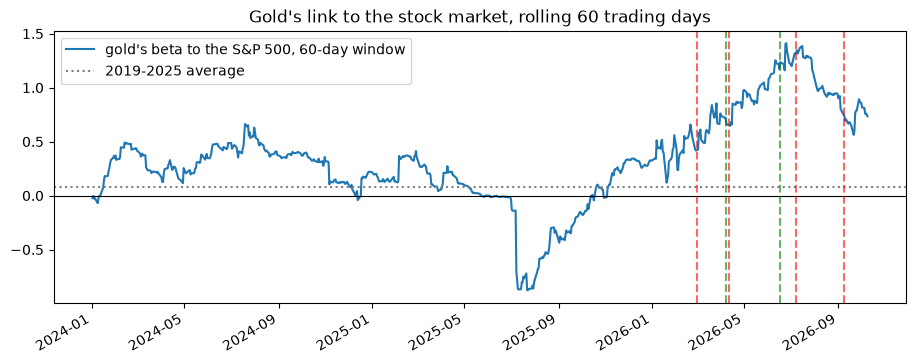

date
2025-06   -0.01
2025-07   -0.81
2025-08   -0.34
2025-09   -0.16
2025-10   -0.02
2025-11    0.33
2025-12    0.32
2026-01    0.56
2026-02    0.42
2026-03    0.76
2026-04    0.97
2026-05    0.98
2026-06    1.22
Freq: M, dtype: float64

In [20]:
window = 60
gold_roll = (hret["gold"].rolling(window).cov(hret["sp500"]) /
             hret["sp500"].rolling(window).var()).loc["2024-01-01":]

fig, ax = plt.subplots(figsize=(11, 4))
gold_roll.plot(ax=ax, label=f"gold's beta to the S&P 500, {window}-day window")
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(beta(hret.loc["2019-01-01":"2025-12-31"], "gold"), color="grey", linestyle=":",
           label="2019-2025 average")
add_event_lines(ax)
ax.set_title(f"Gold's link to the stock market, rolling {window} trading days")
ax.set_xlabel("")
ax.legend(loc="upper left")
plt.savefig("figures/gold_rolling_beta.png", dpi=150, bbox_inches="tight")
plt.show()

# Value at the end of each month around the start of the war
monthly = gold_roll.loc["2025-06-01":"2026-06-30"]
monthly.groupby(monthly.index.to_period("M")).last().round(2)

**Reading the chart.** Gold's link to stocks was mildly positive for much of 2024 (mostly around 0.2 to 0.5), dropped sharply below zero in early July 2025, and then climbed steadily. The sudden drop is not a data error. Each point uses the last 60 trading days, and the drop comes 60 trading days after the April 2025 tariff shock, so it most likely marks those few very turbulent days leaving the window; after that, the measure reflects the weeks around the June 2025 Israel–Iran conflict, when gold rose as stocks fell. This is itself a reminder that this kind of measure can be swayed by a handful of big days. It first rose clearly above its 2019–2025 average around November 2025, about four months before the war, reached about 0.5 by January 2026, and kept rising during the war to a peak of about 1.4 in the summer before falling back to about 0.75 by October. So the war came in the middle of a rise that had already begun, although the link reached its highest level during the war.

### Check: is the 2026 result driven by a few days?

A handful of very large days can make two assets look more closely linked than they usually are. I measure gold's 2026 link to stocks again without the five days with the largest S&P 500 moves (up or down).

In [21]:
war_g = hret.loc["2026-03-02":"2026-10-09", ["sp500", "gold"]].dropna()
biggest = war_g["sp500"].abs().nlargest(5).index
print("Five largest S&P 500 moves in the war period (daily log change x 100):")
print((war_g.loc[biggest].sort_index() * 100).round(2))

rows = []
for label, d in [("all days", war_g), ("without the 5 largest S&P 500 moves", war_g.drop(biggest))]:
    m = smf.ols("gold ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    lo, hi = m.conf_int().loc["sp500"]
    rows.append({"sample": label, "days": len(d),
                 "beta": m.params["sp500"], "ci_low": lo, "ci_high": hi})
pd.DataFrame(rows).round(2)

Five largest S&P 500 moves in the war period (daily log change x 100):
            sp500  gold
date                   
2026-03-26  -1.80 -3.83
2026-03-31   2.87  3.72
2026-04-08   2.52  0.63
2026-06-05  -2.61 -3.72
2026-08-04   1.79  0.66


,sample,days,beta,ci_low,ci_high
0,all days,155,1.02,0.71,1.33
1,without the 5 largest S&P 500 moves,150,0.98,0.57,1.40


**Reading the table.** Gold's 2026 link to stocks hardly changes without the five biggest market days (0.98 instead of 1.02), so it is not driven by a handful of days.

### Check: how mixed was the main before period?

The chart above suggests that the main before period (June 2025 – January 2026) combines a summer when gold moved against stocks with a winter when it moved with them. Here I measure gold's link to stocks separately for the two stretches, and for the whole period again without its five biggest market days.

In [22]:
base_g = calm[["sp500", "gold"]].dropna()
top = base_g["sp500"].abs().nlargest(5).index
print("Five largest S&P 500 moves in the main before period (daily log change x 100):")
print((base_g.loc[top].sort_index() * 100).round(2))

rows = []
for label, d in [("whole before period", base_g),
                 ("whole before period, without the 5 largest S&P 500 moves", base_g.drop(top)),
                 ("summer: Jun - Aug 2025", base_g.loc["2025-06-01":"2025-08-31"]),
                 ("winter: Nov 2025 - Jan 2026", base_g.loc["2025-11-01":"2026-01-30"])]:
    m = smf.ols("gold ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    lo, hi = m.conf_int().loc["sp500"]
    rows.append({"sample": label, "days": len(d), "beta": m.params["sp500"], "ci_low": lo, "ci_high": hi})
pd.DataFrame(rows).round(2)

Five largest S&P 500 moves in the main before period (daily log change x 100):
            sp500  gold
date                   
2025-08-01  -1.65  2.01
2025-10-10  -2.74  1.00
2025-11-10   1.55  2.70
2025-11-13  -1.67 -0.81
2026-01-20  -2.06  3.71


,sample,days,beta,ci_low,ci_high
0,whole before period,167,0.08,-0.29,0.44
1,"whole before period, without the 5 largest S&P...",162,0.25,-0.15,0.66
2,summer: Jun - Aug 2025,62,-0.36,-0.70,-0.02
3,winter: Nov 2025 - Jan 2026,61,0.56,-0.15,1.27


**Reading the table.** The before period really was mixed. Gold moved against stocks in the summer of 2025 (about −0.36, clearly below zero) and with them in the winter just before the war (about 0.56, though with a wide range of uncertainty). The whole-period figure of 0.08 is also pulled down by a few days when stocks fell and gold rose; without the five biggest market days it is about 0.25. So part of the increase measured against the main before period comes from that period being unusually low. Against the winter months just before the war, gold's link to stocks during the conflict (about 1.0) is still higher, but the gap is roughly half as large.

## 9. What happens on the worst days for stocks? (Baur and Lucey, 2010)

This test, widely used in research on safe havens, measures how closely an asset follows stocks on normal days and on the worst days for the stock market in 2019–2025, split into the worst 5%, worst 2.5% and worst 1% of days.

- An asset is a **hedge** if, on average, it does not move with stocks.
- It is a **safe haven** if it does not fall along with stocks on the worst days.

The exact model is given in the Technical notes at the end.

In [23]:
sample = hret.loc["2019-01-01":"2025-12-31", ["sp500", "gold", "bitcoin"]].dropna().copy()

q05, q025, q01 = sample["sp500"].quantile([0.05, 0.025, 0.01])
sample["sp500_q05"]  = sample["sp500"] * (sample["sp500"] <= q05)
sample["sp500_q025"] = sample["sp500"] * (sample["sp500"] <= q025)
sample["sp500_q01"]  = sample["sp500"] * (sample["sp500"] <= q01)

print(f"Thresholds: 5% = {q05:.2%}, 2.5% = {q025:.2%}, 1% = {q01:.2%}")
print("Number of stress days:",
      (sample["sp500"] <= q05).sum(), (sample["sp500"] <= q025).sum(), (sample["sp500"] <= q01).sum())

stress_tests = [("normal days",       "sp500"),
                ("worst 2.5-5% days", "sp500 + sp500_q05"),
                ("worst 1-2.5% days", "sp500 + sp500_q05 + sp500_q025"),
                ("worst 1% days",     "sp500 + sp500_q05 + sp500_q025 + sp500_q01")]

def baur_lucey(data, label):
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500 + sp500_q05 + sp500_q025 + sp500_q01", data=data) \
               .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        print(f"\n=== {asset} ({label}) ===")
        for name, expr in stress_tests:
            t = m.t_test(f"{expr} = 0")
            lo, hi = np.squeeze(t.conf_int())
            print(f"{name:17s} total beta = {float(np.squeeze(t.effect)):6.3f}, "
                  f"95% CI [{lo:6.3f}, {hi:6.3f}], p = {float(np.squeeze(t.pvalue)):.3f}")

baur_lucey(sample, "2019-2025")

Thresholds: 5% = -1.78%, 2.5% = -2.55%, 1% = -3.49%
Number of stress days: 88 44 18

=== gold (2019-2025) ===
normal days       total beta =  0.078, 95% CI [-0.014,  0.170], p = 0.098
worst 2.5-5% days total beta =  0.069, 95% CI [-0.118,  0.256], p = 0.469
worst 1-2.5% days total beta = -0.045, 95% CI [-0.248,  0.158], p = 0.664
worst 1% days     total beta =  0.144, 95% CI [ 0.050,  0.237], p = 0.003

=== bitcoin (2019-2025) ===
normal days       total beta =  0.836, 95% CI [ 0.672,  0.999], p = 0.000
worst 2.5-5% days total beta =  1.001, 95% CI [ 0.195,  1.807], p = 0.015
worst 1-2.5% days total beta =  1.229, 95% CI [ 0.475,  1.983], p = 0.001
worst 1% days     total beta =  1.583, 95% CI [ 0.699,  2.468], p = 0.000


### Check: leaving out the COVID crash

With so few extreme days, a single day (for example, March 12, 2020) can drive the result. I repeat the test without February 20 to April 30, 2020.

In [24]:
covid = (sample.index >= "2020-02-20") & (sample.index <= "2020-04-30")
sample_nc = sample[~covid]
print("Stress days left:",
      (sample_nc["sp500"] <= q05).sum(), (sample_nc["sp500"] <= q025).sum(), (sample_nc["sp500"] <= q01).sum())

baur_lucey(sample_nc, "excluding COVID crash")

Stress days left: 72 29 10

=== gold (excluding COVID crash) ===
normal days       total beta =  0.066, 95% CI [-0.017,  0.150], p = 0.121
worst 2.5-5% days total beta =  0.066, 95% CI [-0.125,  0.257], p = 0.497
worst 1-2.5% days total beta =  0.055, 95% CI [-0.132,  0.242], p = 0.564
worst 1% days     total beta =  0.163, 95% CI [ 0.008,  0.317], p = 0.039

=== bitcoin (excluding COVID crash) ===
normal days       total beta =  0.870, 95% CI [ 0.693,  1.047], p = 0.000
worst 2.5-5% days total beta =  0.980, 95% CI [ 0.156,  1.804], p = 0.020
worst 1-2.5% days total beta =  1.657, 95% CI [ 0.738,  2.576], p = 0.000
worst 1% days     total beta =  1.411, 95% CI [ 0.211,  2.611], p = 0.021


### What did gold and Bitcoin do on the worst days for stocks in 2026?

The test above covers 2019–2025. For 2026, I list the war-period days when the S&P 500 fell by more than about 1.8%, a fall that ranked among the worst 5% of days in 2019–2025, and compare gold's and Bitcoin's average moves on those days with similar days in 2019–2025, in percent.

In [25]:
war_h = hret.loc["2026-03-02":"2026-10-09", ["sp500", "gold", "bitcoin"]].dropna()
stress_2026 = war_h[war_h["sp500"] <= q05]
print(len(stress_2026), f"days in the war period with the S&P 500 down more than {abs(q05):.2%}")
((np.exp(stress_2026) - 1) * 100).round(2)   # simple daily % changes

2 days in the war period with the S&P 500 down more than 1.78%


,sp500,gold,bitcoin
date,,,
2026-03-26,-1.79,-3.76,-3.53
2026-06-05,-2.58,-3.65,-4.51


In [26]:
stress_hist = sample.loc[sample["sp500"] <= q05, ["sp500", "gold", "bitcoin"]]
pd.DataFrame({
    "2019-2025 stress days: average daily change %": ((np.exp(stress_hist) - 1) * 100).mean(),
    "2019-2025: share of days the asset fell": (stress_hist < 0).mean(),
    "2026 stress days: average daily change %": ((np.exp(stress_2026) - 1) * 100).mean(),
    "2026: share of days the asset fell": (stress_2026 < 0).mean(),
}).round(2)

,2019-2025 stress days: average daily change %,2019-2025: share of days the asset fell,2026 stress days: average daily change %,2026: share of days the asset fell
sp500,-3.00,1.00,-2.18,1.0
gold,-0.09,0.62,-3.71,1.0
bitcoin,-3.29,0.76,-4.02,1.0


## 10. Summary of findings

### What I wanted to know

When a war or crisis hits, investors look for assets that protect them from falling stocks. Research separates two kinds of protection: a **hedge** does not move with stocks on average, and a **safe haven** holds its value on the days when stocks fall sharply. Gold is the classic example of both, and some people argue that Bitcoin is "digital gold". I used the 2026 Strait of Hormuz crisis, when fighting around one of the world's most important oil routes sent oil prices sharply higher, to test whether either of them behaved this way.

### In short

Bitcoin behaved like a risky investment rather than a safe haven, as it has since 2019. Gold, unusually, rose and fell with the stock market during the 2026 conflict, but there were too few sharp market falls to tell whether it still protects investors in a crash. These are patterns in prices; on their own they cannot show that the war caused them.

### What I found

**Gold followed the stock market far more than usual.** Over 2019–2025 as a whole, gold's daily moves had little to do with stocks; during the conflict, the two often rose and fell together, with gold moving about as much as stocks. Compared over the same length of time, no other market shock since 2019 comes close, including a similar Israel–Iran conflict in June 2025, and the result is not driven by a handful of big market days.

**But the change began before the war, and its size depends on the comparison.** Gold moved against stocks in the summer of 2025, and its link to stocks began rising around November 2025, about four months before the war, before peaking during the conflict. Measured against the winter months just before the war, the increase is roughly half as large as against June 2025 – January 2026. Against four different "before" periods it is always there, but clearly larger than chance for only two of them: the main period and the 180 days before the war.

**The result holds with a direct measure of interest rates.** One possible reason for the change is that gold and stocks were both reacting to the same news about interest rates. Replacing the bond fund with the 10-year inflation-adjusted interest rate barely changes the result. Gold did become more sensitive to interest rates during the conflict, but allowing for this leaves its closer link with stocks in place. This cannot rule out every role for interest rates.

**On the two sharp market falls during the conflict, gold fell too,** and by more than stocks. On similar days in 2019–2025 it was roughly flat on average.

**For Bitcoin, the main evidence is its long-run behaviour.** Since 2019 it has tended to move about as much as US stocks, and even more than stocks on their very worst days. In 2026 it still moved about as much as stocks or more, whether its price is taken at the US market close or later in the evening. On individual conflict days, it rose about 6% more than expected in the two days after the war began, but that is not clearly unusual once the number of comparisons is taken into account, and an apparent fall after the ceasefire disappears when its price is taken at the US close.

**Bitcoin and gold moved more closely together during the conflict.** Their shared link to stocks explains part of this, but not all.

### What this means

Whether an asset behaves as a hedge is not a fixed fact; it can change from one crisis to the next, so investors should not assume gold will always move independently of stocks. I could not establish why 2026 was different; a shared reaction to news about long-term interest rates does not appear to be the main reason, although this check cannot rule it out. One possibility, which I did not test, is that some investors sold gold to lock in profits after its sharp rise in 2025.

### How confident am I?

- The 2026 conflict produced only six clear events and two sharp stock-market falls to study.
- Some results depend on which "before" period is used, and the main one is itself mixed, so I report several and also compare with 2019–2025.
- Bitcoin's main daily price is recorded in the evening, after the US close. Repeating the timing-sensitive tests with its 4 p.m. price changes two Bitcoin results, as described above.
- Event dates come from news timelines, and I did not check for other economic news released on the same days.
- I use funds that track stocks, gold and oil as stand-ins for the assets themselves.

## 11. Technical notes

**Definitions.**
- Daily returns are log returns. Cumulative returns over a window are converted to simple percentage changes as exp(sum of log returns) − 1.
- **Beta** to the S&P 500 is the slope from regressing an asset's daily return on the S&P 500's daily return (0 = no relation, 1 = moves one-for-one).
- OLS regressions use Newey-West (HAC, 5 lags) standard errors, following Baur and Lucey (2010).
- Units: columns labelled `_log_pct`, the constant-mean event table and the lists of individual days show daily log returns (or their sums) × 100. The 2026 stress-day tables show simple percentage changes.
- Bitcoin's daily price is the close of the UTC day (8 p.m. New York time in summer, 7 p.m. in winter). Section 7 rebuilds it at 4 p.m. ET from hourly bars.

**Event study (Section 4).** Abnormal return = actual return − before-period mean. CAR(0,+1) is the sum over the first US trading day on or after the event and the next day; t = CAR / (σ√2), with σ the before-period standard deviation. The market-model version uses abnormal return = r − (α + β·r_S&P), with α and β estimated in the before period. Empirical p-value = (number of rolling same-length windows in the estimation sample with an |abnormal return| at least as large + 1) / (number of windows + 1). The two-day window CAR(0,+1) is the main test: Holm's method adjusts its 12 p-values (six events × two assets) in the `_main` columns, and the `_holm` columns adjust all 36 windows. The two-day windows are repeated with Bitcoin's 4 p.m. price in Section 7. Event windows with missing data stop the code with an error.

**Correlations (Section 5).** The partial correlation is the correlation of residuals after regressing each asset on the S&P 500 within each period.

**Interaction regressions (Section 6).**
- Pooled model: asset ~ war × (S&P 500 + dollar + oil + TIP), so every slope may differ during the conflict; the war×S&P 500 coefficient is the change in beta. The same model is used for each of the four before periods.
- Section 7 also estimates a stocks-only version (asset ~ S&P 500 + war + war×S&P 500) to compare Bitcoin's midnight UTC and 4 p.m. prices.
- Real-yield check: the full model with TIP replaced by the daily change in the 10-year real yield (FRED series DFII10, percentage points), on days when both the stock and bond markets were open. For readability the real-yield slopes are also shown as the % move in the asset per 10 basis point rise in the yield (slope × 0.10 × 100).

**Rolling beta and outliers (Section 8).** Rolling beta = 60-day rolling covariance with the S&P 500 / 60-day rolling variance of the S&P 500. The outlier checks drop the five days with the largest absolute S&P 500 returns in the war period and, separately, in the main before period. The before period is also split into June–August 2025 and November 2025 – January 2026.

**Baur and Lucey (2010) test (Section 9).** asset = a + b1·S&P + b2·S&P·D(5%) + b3·S&P·D(2.5%) + b4·S&P·D(1%), where D(q) = 1 on days when the S&P 500 return is in its worst q% of 2019–2025. Because the groups are nested, the total beta is b1 on normal days, b1 + b2 on the worst 2.5–5% of days, b1 + b2 + b3 on the worst 1–2.5%, and b1 + b2 + b3 + b4 on the worst 1%. Total betas are reported with 95% confidence intervals. Hedge: b1 ≤ 0. Safe haven: total beta ≤ 0 in a stress band (strong if significantly below zero, weak if not significantly different from zero).

**Key numbers.**

| Measure | Sample | Result |
|---|---|---|
| Gold's beta to the S&P 500, before period (Jun 2025 – Jan 2026) | 167 days | 0.08 (95% CI −0.29 to 0.44) |
| Same, without its 5 largest S&P 500 days / summer (Jun – Aug 2025) / winter (Nov 2025 – Jan 2026) | 162 / 62 / 61 days | 0.25 (−0.15 to 0.66) / −0.36 (−0.70 to −0.02) / 0.56 (−0.15 to 1.27) |
| Gold's beta to the S&P 500, conflict period (Mar 2 – Oct 9, 2026), S&P 500 only | 155 days | 1.02 (95% CI 0.71 to 1.33) |
| Change in gold's beta, conflict vs. before period (S&P 500, oil, dollar and TIPS all allowed to change) | 167 + 155 days | +0.74 (95% CI 0.17 to 1.30) |
| Same change against the last 60 / 120 / 180 pre-war trading days | 60 / 120 / 180 + 155 days | +0.55 / +0.48 / +0.66 (p = 0.25 / 0.15 / 0.03) |
| Same change, 10-year real yield (FRED DFII10) in place of TIPS | 320 days | +0.76 (95% CI 0.19 to 1.33), vs. +0.79 with TIPS on the same days |
| Gold's move per 10 bp rise in the 10-year real yield, before / conflict (full model) | 320 days | +0.00% / −0.41% |
| Gold's 60-day rolling beta, end of Nov 2025 / Jan 2026 / Jun 2026 | 60-day windows | 0.33 / 0.56 / 1.22 |
| Gold's beta, conflict period, without the 5 largest S&P 500 days | 150 days | 0.98 (95% CI 0.57 to 1.40) |
| Gold's beta, first 40 trading days of the 2026 shock | 40 days | 0.93 (95% CI 0.52 to 1.33) |
| Gold's beta, all days 2019–2025 | 1,759 days | 0.08 (95% CI 0.03 to 0.14) |
| 2026 days with an S&P 500 log return below −1.78% (2019–2025 worst-5% threshold) | 2 days | Gold fell on both (average −3.7%, S&P 500 −2.2%) |
| Gold on the worst 5% of S&P 500 days, 2019–2025 | about 88 days | Average −0.1% |
| Bitcoin's beta to the S&P 500, all days 2019–2025 | 1,759 days | 1.05 (95% CI 0.75 to 1.36) |
| Bitcoin's total beta, Baur–Lucey test, 2019–2025 | normal days vs. worst 1% | 0.84 vs. 1.58 |
| Bitcoin's beta, conflict period (midnight UTC / 4 p.m. ET price) | 155 days | 1.14 (95% CI 0.76 to 1.52) / 1.37 |
| Change in Bitcoin's beta, conflict vs. before period, S&P 500 only (midnight UTC / 4 p.m. ET price) | 167 + 155 days | −0.73 (95% CI −1.27 to −0.19) / −0.34 (95% CI −0.88 to 0.20) |
| Bitcoin–gold correlation, before vs. conflict | 167 / 155 days | 0.10 vs. 0.43; partial correlation controlling for the S&P 500: 0.10 vs. 0.29 |

The 1.02 and +0.74 are different statistics: the first is gold's beta within the conflict period from a model with the S&P 500 only; the second is the increase relative to the before period in a model with the S&P 500, oil, the dollar and TIPS, all allowed to change during the conflict.

**Other results.**

- **Units:** abnormal returns and CARs are sums of daily log returns × 100 (log percent); stress-day averages are simple percentage changes.
- **Event study, constant-mean model (2-day windows, CAR(0,+1)):** Bitcoin's abnormal returns were never significant (all |t| < 2). Oil moved +10.2% (t = 4.05) at the start of the war and −10.0% (t = −3.99) after the ceasefire.
- **Event study, market model (1-, 2- and 3-day windows, empirical p-values, Holm-adjusted across 36 windows):** with the before-period beta, Bitcoin's abnormal return was +4.6% (p = 0.04) on the first day of the war and −5.5% (p = 0.02) on the first day of the ceasefire, but no window is significant after the Holm adjustment (smallest adjusted p = 0.22). These historical comparisons and multiple-testing adjustments are exploratory and remain affected by changing volatility and overlapping windows. With Bitcoin's 4 p.m. ET price, the two-day abnormal return is +6.0% after the start of the war (p = 0.04; Holm-adjusted across six events, 0.25) and −0.3% after the ceasefire (p = 0.90).
- **Baur and Lucey (2010) test, 2019–2025:** gold's total beta is not significantly different from zero on normal days or on days in the worst 2.5–5% and 1–2.5% of stock-market returns, and slightly positive on the worst 1% of days (0.14, p = 0.003). Both assets' results hold when the COVID crash is excluded.
- **Correlations** are supporting evidence only, because they rise mechanically with volatility (Forbes and Rigobon, 2002).

## References

- Baur, D. G., & Lucey, B. M. (2010). Is gold a hedge or a safe haven? An analysis of stocks, bonds and gold. *Financial Review*, 45(2), 217–229.
- Baur, D. G., & Smales, L. A. (2020). Hedging geopolitical risk with precious metals. *Journal of Banking & Finance*, 117, 105823.
- Bouri, E., Molnár, P., Azzi, G., Roubaud, D., & Hagfors, L. I. (2017). On the hedge and safe haven properties of Bitcoin: Is it really more than a diversifier? *Finance Research Letters*, 20, 192–198.
- Conlon, T., & McGee, R. (2020). Safe haven or risky hazard? Bitcoin during the Covid-19 bear market. *Finance Research Letters*, 35, 101607.
- Forbes, K. J., & Rigobon, R. (2002). No contagion, only interdependence: Measuring stock market comovements. *Journal of Finance*, 57(5), 2223–2261.
- Klein, T., Pham Thu, H., & Walther, T. (2018). Bitcoin is not the New Gold – A comparison of volatility, correlation, and portfolio performance. *International Review of Financial Analysis*, 59, 105–116.
- MacKinlay, A. C. (1997). Event studies in economics and finance. *Journal of Economic Literature*, 35(1), 13–39.
- Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.